# OceanEmbed — Subsurface Temperature Reconstruction
**Full pipeline**: Data ingestion → Preprocessing (Prefect) → Satellite Embedding → U-Net+BiConvGRU+Attention → MLflow/W&B → ARGO Validation → XAI → Model Save

**Domain**: North Indian Ocean | 5°N–30°N, 45°E–105°E | Daily, 0.25° | 2011–2022

**Inputs**: SST (OSTIA), SSS (SMOS/SMAP), SSH/SLA (DUACS), Currents (MULTIOBS), Winds (CMEMS winds)

**Target**: GLORYS12 thetao at 15 standard depths (0–1000 m)

---
**Prerequisites** (run once in your environment):
```
pip install copernicusmarine xarray netCDF4 zarr scipy numpy pandas \
            prefect torch torchvision scikit-learn mlflow wandb \
            captum matplotlib cartopy tqdm
```

### Mount Google Drive
We will mount your Google Drive to save the downloaded USA-specific dataset directly into it.

In [ ]:
from google.colab import drive
import os


# Define a path inside Google Drive to save USA data
usa_drive_dir = '/content/drive/MyDrive/NASA_USA_Data'
os.makedirs(usa_drive_dir, exist_ok=True)
print(f"Target Google Drive directory created: {usa_drive_dir}")

Target Google Drive directory created: /content/drive/MyDrive/NASA_USA_Data


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Search and Download USA Data via earthaccess
Using a standard continental US (CONUS) bounding box, we query and download data into Google Drive.

In [ ]:
import earthaccess

# Authenticate if not already persisted in the session
earthaccess.login(strategy="interactive", persist=True)

# Define a USA bounding box (approx. CONUS: min_lon, min_lat, max_lon, max_lat)
USA_BOUNDING_BOX = (-125.0, 24.0, -66.0, 49.0)
USA_START_DATE = "2020-01-01"
USA_END_DATE = "2020-01-02"

# Search for CCMP Winds (or another target dataset) within USA bounds
print("Searching for winds dataset over continental USA...")
usa_results = earthaccess.search_data(
    short_name="CCMP_WINDS_10M6HR_L4_V3.1",
    temporal=(USA_START_DATE, USA_END_DATE),
    bounding_box=USA_BOUNDING_BOX
)

print(f"Found {len(usa_results)} granules over the USA region.")
if len(usa_results) > 0:
    downloaded = earthaccess.download(usa_results, local_path=usa_drive_dir)
    print(f"Successfully saved {len(downloaded)} files directly into your Google Drive: {usa_drive_dir}")

Searching for winds dataset over continental USA...
Found 2 granules over the USA region.


QUEUEING TASKS | :   0%|          | 0/2 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/2 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/2 [00:00<?, ?it/s]

Successfully saved 2 files directly into your Google Drive: /content/drive/MyDrive/NASA_USA_Data


In [ ]:
import os
import glob
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = '/content/drive/MyDrive/NASA_USA_Data'

def inspect_and_explore_datasets(data_dir):
    nc_files = glob.glob(os.path.join(data_dir, "*.nc"))

    if not nc_files:
        print(f"No NetCDF (.nc) files found in {data_dir}")
        return

    print(f"Found {len(nc_files)} NetCDF file(s) in '{data_dir}':\n")
    for f in nc_files:
        print(f" - {os.path.basename(f)}")
    print("=" * 70)

    for file_path in sorted(nc_files):
        filename = os.path.basename(file_path)
        print(f"\n==================================================")
        print(f" File: {filename}")
        print(f"==================================================")

        try:
            ds = xr.open_dataset(file_path)

            # 1. Dataset Overview & Dimensions
            print("\n--- DIMENSIONS ---")
            for dim, size in ds.dims.items():
                print(f"  * {dim}: {size}")

            # 2. Data Variables
            print("\n--- DATA VARIABLES & SHAPES ---")
            for var in ds.data_vars:
                var_da = ds[var]
                unit = var_da.attrs.get('units', 'No unit specified')
                long_name = var_da.attrs.get('long_name', var)
                print(f"  * {var}: shape={var_da.shape}, dtype={var_da.dtype}")
                print(f"    └─ Description: {long_name} [{unit}]")

            # 3. Spatial & Temporal Coverage
            print("\n--- COORDINATE BOUNDS ---")
            for coord in ds.coords:
                coord_data = ds[coord].values
                if coord_data.dtype.kind in ['f', 'i']:
                    print(f"  * {coord}: Min = {coord_data.min():.3f}, Max = {coord_data.max():.3f}")
                elif coord_data.dtype.kind == 'M':  # Datetime
                    print(f"  * {coord}: Start = {coord_data.min()}, End = {coord_data.max()}")

            # 4. Missing Values / NaNs Check
            print("\n--- DATA INTEGRITY / MISSING VALUES ---")
            for var in ds.data_vars:
                # Check NaNs on a sample slice if dataset is large
                null_count = int(ds[var].isnull().sum().values)
                total_count = ds[var].size
                pct_missing = (null_count / total_count) * 100
                print(f"  * {var}: {null_count}/{total_count} missing values ({pct_missing:.2f}% land/mask/NaN)")

            # 5. Summary Statistics for Primary Variables
            print("\n--- SUMMARY STATS ---")
            df_summary = ds.to_dataframe().describe().T[['mean', 'std', 'min', '50%', 'max']]
            print(df_summary)

            # 6. Quick Visual Plot of First Primary Variable
            primary_var = list(ds.data_vars)[0]
            fig, ax = plt.subplots(figsize=(10, 5))

            # Select first time step if time dimension exists
            if 'time' in ds[primary_var].dims and ds[primary_var].sizes['time'] > 0:
                sample_slice = ds[primary_var].isel(time=0)
            else:
                sample_slice = ds[primary_var]

            # Plot spatial map or 1D array
            sample_slice.plot(ax=ax, cmap="viridis")
            plt.title(f"Spatial Field: {primary_var} ({filename})")
            plt.grid(True, linestyle="--", alpha=0.5)
            plt.show()

        except Exception as e:
            print(f"Error reading {filename}: {e}")

if __name__ == "__main__":
    inspect_and_explore_datasets(DATA_DIR)

No NetCDF (.nc) files found in /content/drive/MyDrive/NASA_USA_Data


## Cell 0 — Credentials & Global Config
Set your Copernicus Marine credentials here. Everything else derives from these constants.

In [ ]:
# ─── CREDENTIALS ──────────────────────────────────────────────────────────────
COP_USER = "franz"   # replace
COP_PASS = "Joes@9092443143"   # replace
WANDB_KEY = "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"  # replace or set env var WANDB_API_KEY

# ─── DOMAIN ───────────────────────────────────────────────────────────────────
LON_MIN, LON_MAX = 45.0, 105.0
LAT_MIN, LAT_MAX =  5.0,  30.0

# ─── TIME SPLITS ──────────────────────────────────────────────────────────────
TRAIN_START, TRAIN_END = "2011-01-01", "2019-12-31"
VAL_START,   VAL_END   = "2020-01-01", "2020-12-31"
TEST_START,  TEST_END  = "2021-01-01", "2022-12-31"

# ─── TARGET DEPTHS (metres) ───────────────────────────────────────────────────
TARGET_DEPTHS = [0, 5, 10, 20, 30, 50, 75, 100, 125, 150, 200, 300, 500, 700, 1000]
N_DEPTHS = len(TARGET_DEPTHS)  # 15

# ─── GRID (padded to be divisible by 8 for 3-level U-Net) ────────────────────
# Native: lat 101 pts, lon 241 pts at 0.25°
# Padded: 104 x 248
PAD_LAT, PAD_LON = 104, 248

# ─── PATHS ────────────────────────────────────────────────────────────────────
import os
DATA_DIR  = "./data/raw"
PROC_DIR  = "./data/processed"
CKPT_DIR  = "./checkpoints"
MODEL_DIR = "./models"
for d in [DATA_DIR, PROC_DIR, CKPT_DIR, MODEL_DIR]:
    os.makedirs(d, exist_ok=True)
print("Config OK. Directories created.")

Config OK. Directories created.


Found 5 NetCDF file(s) in '/content/drive/MyDrive/NASA_USA_Data':

 - CCMP_Wind_Analysis_20200101_V03.1_L4.nc
 - CCMP_Wind_Analysis_20200102_V03.1_L4.nc
 - c3s_obs-sl_glo_phy-ssh_my_twosat-l4-duacs-0.25deg_P1D_1791032657361.nc
 - cmems_obs-mob_glo_phy-sss_my_multi_P1D_1791032524147.nc
 - METOFFICE-GLO-SST-L4-REP-OBS-SST_1791032430680.nc

 File: CCMP_Wind_Analysis_20200101_V03.1_L4.nc

--- DIMENSIONS ---
  * time: 4
  * latitude: 720
  * longitude: 1440

--- DATA VARIABLES & SHAPES ---
  * uwnd: shape=(4, 720, 1440), dtype=float32
    └─ Description: u-wind vector component at 10 meters [m s-1]
  * vwnd: shape=(4, 720, 1440), dtype=float32
    └─ Description: v-wind vector component at 10 meters [m s-1]
  * ws: shape=(4, 720, 1440), dtype=float32
    └─ Description: wind speed at 10 meters [m s-1]
  * nobs: shape=(4, 720, 1440), dtype=float32
    └─ Description: number of observations used to derive wind vector components [No unit specified]

--- COORDINATE BOUNDS ---
  * latitude: Min 

/tmp/ipykernel_8487/1258802061.py:32: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  for dim, size in ds.dims.items():
<frozen _collections_abc>:899: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.


  * uwnd: 529920/4147200 missing values (12.78% land/mask/NaN)
  * vwnd: 529920/4147200 missing values (12.78% land/mask/NaN)
  * ws: 529920/4147200 missing values (12.78% land/mask/NaN)
  * nobs: 529920/4147200 missing values (12.78% land/mask/NaN)

--- SUMMARY STATS ---
          mean       std        min       50%        max
uwnd  0.105597  5.438986 -31.068789 -0.142622  30.473003
vwnd -0.124651  5.030797 -41.170956 -0.115946  30.184813
ws    6.292659  3.936946   0.001788  5.945854  41.174622
nobs  1.116114  1.375626   0.000000  0.000000   8.000000


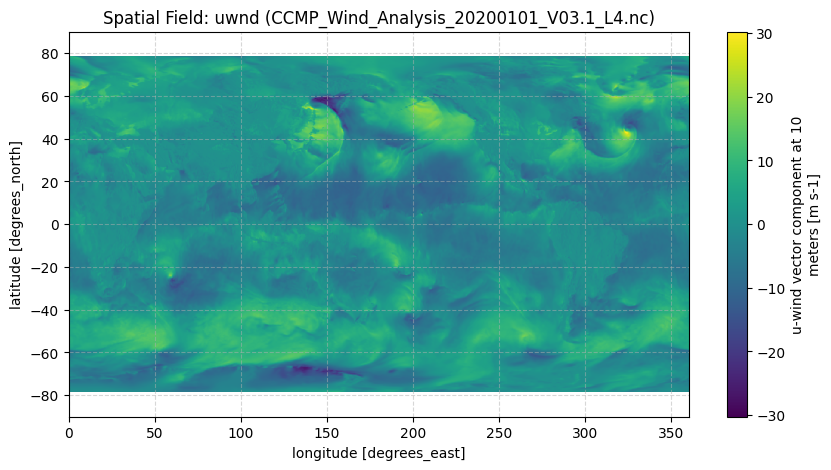


 File: CCMP_Wind_Analysis_20200102_V03.1_L4.nc

--- DIMENSIONS ---
  * time: 4
  * latitude: 720
  * longitude: 1440

--- DATA VARIABLES & SHAPES ---
  * uwnd: shape=(4, 720, 1440), dtype=float32
    └─ Description: u-wind vector component at 10 meters [m s-1]
  * vwnd: shape=(4, 720, 1440), dtype=float32
    └─ Description: v-wind vector component at 10 meters [m s-1]
  * ws: shape=(4, 720, 1440), dtype=float32
    └─ Description: wind speed at 10 meters [m s-1]
  * nobs: shape=(4, 720, 1440), dtype=float32
    └─ Description: number of observations used to derive wind vector components [No unit specified]

--- COORDINATE BOUNDS ---
  * latitude: Min = -89.875, Max = 89.875
  * longitude: Min = 0.125, Max = 359.875
  * time: Start = 2020-01-02T00:00:00.000000000, End = 2020-01-02T18:00:00.000000000

--- DATA INTEGRITY / MISSING VALUES ---


/tmp/ipykernel_8487/1258802061.py:32: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  for dim, size in ds.dims.items():
<frozen _collections_abc>:899: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.


  * uwnd: 529920/4147200 missing values (12.78% land/mask/NaN)
  * vwnd: 529920/4147200 missing values (12.78% land/mask/NaN)
  * ws: 529920/4147200 missing values (12.78% land/mask/NaN)
  * nobs: 529920/4147200 missing values (12.78% land/mask/NaN)

--- SUMMARY STATS ---
          mean       std        min       50%        max
uwnd  0.083219  5.377422 -27.289097 -0.123427  31.422815
vwnd -0.154953  4.974025 -45.061432 -0.119039  28.585020
ws    6.227358  3.882827   0.001118  5.871055  45.844154
nobs  1.130731  1.404746   0.000000  0.000000   8.000000


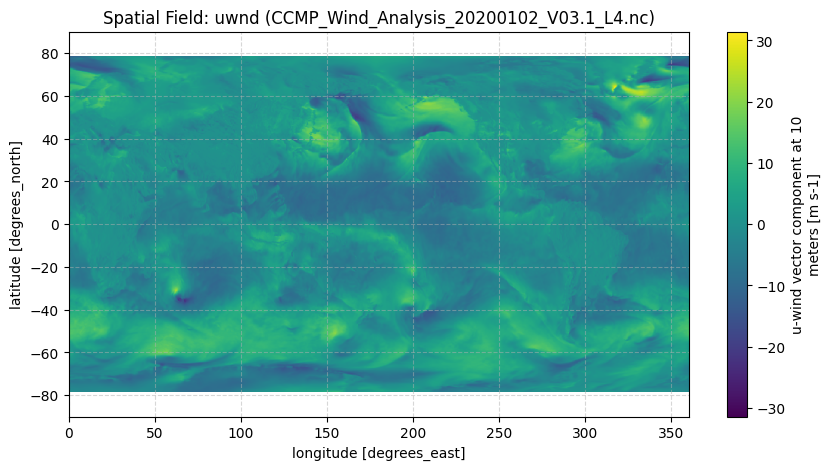


 File: METOFFICE-GLO-SST-L4-REP-OBS-SST_1791032430680.nc

--- DIMENSIONS ---
  * time: 1
  * latitude: 3600
  * longitude: 7200

--- DATA VARIABLES & SHAPES ---
  * analysed_sst: shape=(1, 3600, 7200), dtype=float32
    └─ Description: Analysed sea surface temperature [kelvin]
  * analysis_error: shape=(1, 3600, 7200), dtype=float32
    └─ Description: Estimated error standard deviation of analysed sst [kelvin]
  * mask: shape=(1, 3600, 7200), dtype=float32
    └─ Description: Land sea ice lake bit mask []
  * sea_ice_fraction: shape=(1, 3600, 7200), dtype=float32
    └─ Description: Sea ice area fraction [1]

--- COORDINATE BOUNDS ---
  * time: Start = 2026-03-31T00:00:00.000000000, End = 2026-03-31T00:00:00.000000000
  * latitude: Min = -89.975, Max = 89.975
  * longitude: Min = -179.975, Max = 179.975

--- DATA INTEGRITY / MISSING VALUES ---


/tmp/ipykernel_8487/1258802061.py:32: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  for dim, size in ds.dims.items():
<frozen _collections_abc>:899: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.


  * analysed_sst: 8678335/25920000 missing values (33.48% land/mask/NaN)
  * analysis_error: 8678335/25920000 missing values (33.48% land/mask/NaN)
  * mask: 0/25920000 missing values (0.00% land/mask/NaN)
  * sea_ice_fraction: 8678335/25920000 missing values (33.48% land/mask/NaN)

--- SUMMARY STATS ---
                        mean        std         min         50%         max
analysed_sst      287.291351  21.918493  271.149994  288.509979  305.639984
analysis_error      0.358384   0.302177    0.100000    0.240000    3.670000
mask                2.293962   2.441866    1.000000    1.000000   14.000000
sea_ice_fraction    0.160604   0.351160    0.000000    0.000000    1.000000


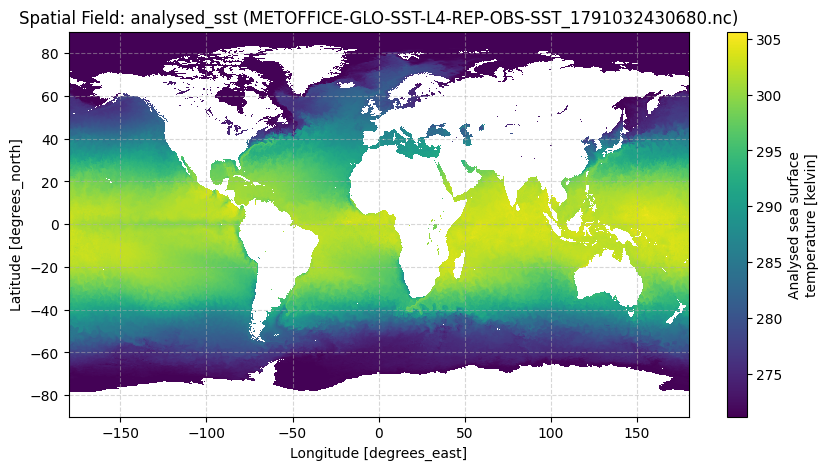


 File: c3s_obs-sl_glo_phy-ssh_my_twosat-l4-duacs-0.25deg_P1D_1791032657361.nc

--- DIMENSIONS ---
  * time: 1
  * latitude: 720
  * longitude: 1440

--- DATA VARIABLES & SHAPES ---
  * adt: shape=(1, 720, 1440), dtype=float32
    └─ Description: Absolute dynamic topography [m]
  * err_sla: shape=(1, 720, 1440), dtype=float32
    └─ Description: Formal mapping error [m]
  * err_ugosa: shape=(1, 720, 1440), dtype=float32
    └─ Description: Formal mapping error on zonal geostrophic velocity anomalies [m/s]
  * err_vgosa: shape=(1, 720, 1440), dtype=float32
    └─ Description: Formal mapping error on meridional geostrophic velocity anomalies [m/s]
  * flag_ice: shape=(1, 720, 1440), dtype=float32
    └─ Description: Ice Flag for a 15% criterion of ice concentration []
  * sla: shape=(1, 720, 1440), dtype=float32
    └─ Description: Sea level anomaly [m]
  * tpa_correction: shape=(1,), dtype=float32
    └─ Description: TOPEX-A instrumental drift correction derived from altimetry and tide 

/tmp/ipykernel_8487/1258802061.py:32: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  for dim, size in ds.dims.items():
<frozen _collections_abc>:899: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.


  * adt: 424825/1036800 missing values (40.97% land/mask/NaN)
  * err_sla: 439686/1036800 missing values (42.41% land/mask/NaN)
  * err_ugosa: 439686/1036800 missing values (42.41% land/mask/NaN)
  * err_vgosa: 439686/1036800 missing values (42.41% land/mask/NaN)
  * flag_ice: 422541/1036800 missing values (40.75% land/mask/NaN)
  * sla: 422541/1036800 missing values (40.75% land/mask/NaN)
  * tpa_correction: 1/1 missing values (100.00% land/mask/NaN)
  * ugos: 424846/1036800 missing values (40.98% land/mask/NaN)
  * ugosa: 422556/1036800 missing values (40.76% land/mask/NaN)
  * vgos: 424853/1036800 missing values (40.98% land/mask/NaN)
  * vgosa: 422565/1036800 missing values (40.76% land/mask/NaN)

--- SUMMARY STATS ---
                    mean       std     min     50%        max
adt             0.350133  0.745029 -1.4557  0.5755   1.896500
err_sla         0.018628  0.013663  0.0037  0.0146   0.234500
err_ugosa       0.105295  0.481842  0.0051  0.0454  53.601200
err_vgosa       0.1

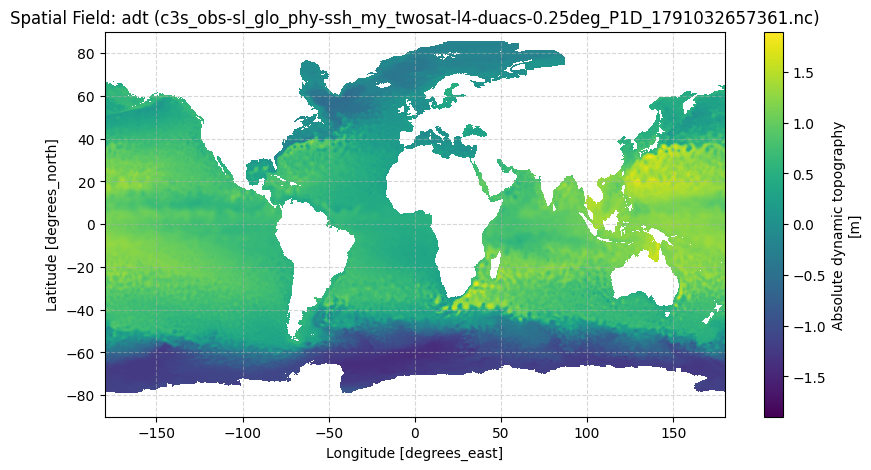


 File: cmems_obs-mob_glo_phy-sss_my_multi_P1D_1791032524147.nc

--- DIMENSIONS ---
  * time: 1
  * depth: 1
  * latitude: 1440
  * longitude: 2880

--- DATA VARIABLES & SHAPES ---
  * dos: shape=(1, 1, 1440, 2880), dtype=float32
    └─ Description: Sea surface density [kg/m3]
  * dos_error: shape=(1, 1, 1440, 2880), dtype=float32
    └─ Description: Sea surface density error [kg/m3]
  * sea_ice_fraction: shape=(1, 1, 1440, 2880), dtype=float32
    └─ Description: Sea ice area fraction [percent]
  * sos: shape=(1, 1, 1440, 2880), dtype=float32
    └─ Description: Sea surface salinity [.001]
  * sos_error: shape=(1, 1, 1440, 2880), dtype=float32
    └─ Description: Sea surface salinity error [0.001]

--- COORDINATE BOUNDS ---
  * time: Start = 2024-12-15T00:00:00.000000000, End = 2024-12-15T00:00:00.000000000
  * depth: Min = -0.000, Max = -0.000
  * latitude: Min = -89.938, Max = 89.938
  * longitude: Min = -179.938, Max = 179.938

--- DATA INTEGRITY / MISSING VALUES ---


/tmp/ipykernel_8487/1258802061.py:32: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  for dim, size in ds.dims.items():
<frozen _collections_abc>:899: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.


  * dos: 1421676/4147200 missing values (34.28% land/mask/NaN)
  * dos_error: 0/4147200 missing values (0.00% land/mask/NaN)
  * sea_ice_fraction: 1413488/4147200 missing values (34.08% land/mask/NaN)
  * sos: 1418333/4147200 missing values (34.20% land/mask/NaN)
  * sos_error: 0/4147200 missing values (0.00% land/mask/NaN)

--- SUMMARY STATS ---
                         mean       std          min          50%          max
dos               1024.717651  2.362356  1002.737366  1025.008423  1029.848511
dos_error            2.531043  2.982475     0.101796     0.357947     6.680000
sea_ice_fraction     0.162057  0.348953     0.000000     0.000000     1.000000
sos                 33.980255  2.482441     5.690685    34.297203    40.000000
sos_error            2.572886  2.918835     0.127245     0.441226     6.680000


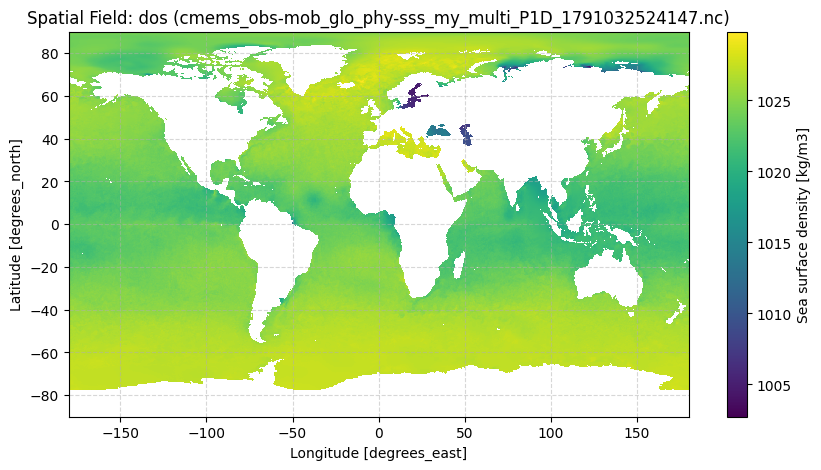

In [ ]:
import os
import glob
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = '/content/drive/MyDrive/NASA_USA_Data'

def inspect_and_explore_datasets(data_dir):
    nc_files = glob.glob(os.path.join(data_dir, "*.nc"))

    if not nc_files:
        print(f"No NetCDF (.nc) files found in {data_dir}")
        return

    print(f"Found {len(nc_files)} NetCDF file(s) in '{data_dir}':\n")
    for f in nc_files:
        print(f" - {os.path.basename(f)}")
    print("=" * 70)

    for file_path in sorted(nc_files):
        filename = os.path.basename(file_path)
        print(f"\n==================================================")
        print(f" File: {filename}")
        print(f"==================================================")

        try:
            ds = xr.open_dataset(file_path)

            # 1. Dataset Overview & Dimensions
            print("\n--- DIMENSIONS ---")
            for dim, size in ds.dims.items():
                print(f"  * {dim}: {size}")

            # 2. Data Variables
            print("\n--- DATA VARIABLES & SHAPES ---")
            for var in ds.data_vars:
                var_da = ds[var]
                unit = var_da.attrs.get('units', 'No unit specified')
                long_name = var_da.attrs.get('long_name', var)
                print(f"  * {var}: shape={var_da.shape}, dtype={var_da.dtype}")
                print(f"    └─ Description: {long_name} [{unit}]")

            # 3. Spatial & Temporal Coverage
            print("\n--- COORDINATE BOUNDS ---")
            for coord in ds.coords:
                coord_data = ds[coord].values
                if coord_data.dtype.kind in ['f', 'i']:
                    print(f"  * {coord}: Min = {coord_data.min():.3f}, Max = {coord_data.max():.3f}")
                elif coord_data.dtype.kind == 'M':  # Datetime
                    print(f"  * {coord}: Start = {coord_data.min()}, End = {coord_data.max()}")

            # 4. Missing Values / NaNs Check
            print("\n--- DATA INTEGRITY / MISSING VALUES ---")
            for var in ds.data_vars:
                # Check NaNs on a sample slice if dataset is large
                null_count = int(ds[var].isnull().sum().values)
                total_count = ds[var].size
                pct_missing = (null_count / total_count) * 100
                print(f"  * {var}: {null_count}/{total_count} missing values ({pct_missing:.2f}% land/mask/NaN)")

            # 5. Summary Statistics for Primary Variables
            print("\n--- SUMMARY STATS ---")
            df_summary = ds.to_dataframe().describe().T[['mean', 'std', 'min', '50%', 'max']]
            print(df_summary)

            # 6. Quick Visual Plot of First Primary Variable
            primary_var = list(ds.data_vars)[0]
            fig, ax = plt.subplots(figsize=(10, 5))

            # Select first time step if time dimension exists
            if 'time' in ds[primary_var].dims and ds[primary_var].sizes['time'] > 0:
                sample_slice = ds[primary_var].isel(time=0)
            else:
                sample_slice = ds[primary_var]

            # Plot spatial map or 1D array
            sample_slice.plot(ax=ax, cmap="viridis")
            plt.title(f"Spatial Field: {primary_var} ({filename})")
            plt.grid(True, linestyle="--", alpha=0.5)
            plt.show()

        except Exception as e:
            print(f"Error reading {filename}: {e}")

if __name__ == "__main__":
    inspect_and_explore_datasets(DATA_DIR)

## Cell 1 — Data Ingestion from Copernicus Marine
Downloads 6 datasets for 2011–2022 subsetted to the North Indian Ocean domain.
Uses **lazy open** first to inspect, then `to_netcdf` year-by-year to avoid OOM.

In [ ]:
!pip install copernicusmarine

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.8/135.8 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.0/140.0 kB 11.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 376.9/376.9 kB 18.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.0/16.0 MB 45.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.5/230.5 kB 14.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 61.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 kB 5.9 MB/s eta 0:00:00


In [ ]:
import copernicusmarine
import xarray as xr
import numpy as np

# ─── Dataset registry ─────────────────────────────────────────────────────────
# All IDs confirmed from copernicusmarine.describe() in prior session.
DATASETS = {
    # GLORYS12 — subsurface temperature TARGET
    # Product: GLOBAL_MULTIYEAR_PHY_001_030 | 0.083° | 50 levels | 1993–ongoing
    "glorys": {
        "dataset_id": "cmems_mod_glo_phy_my_0.083deg_P1D-m",
        "variables": ["thetao"],
        "minimum_depth": 0.0,
        "maximum_depth": 1000.0,
    },
    # OSTIA SST — reprocessed | Product: SST_GLO_SST_L4_REP_OBSERVATIONS_010_011
    # 0.05° daily | 1981–2022-05-31
    "sst": {
        "dataset_id": "METOFFICE-GLO-SST-L4-REP-OBS-SST",
        "variables": ["analysed_sst"],
    },
    # SSS — SMOS+SMAP multi-sensor MY | Product: MULTIOBS_GLO_PHY_S_SURFACE_MYNRT_015_013
    # 0.125° daily | 1993–ongoing
    "sss": {
        "dataset_id": "cmems_obs-mob_glo_phy-sss_my_multi_P1D",
        "variables": ["sos"],
    },
    # SSH/SLA — DUACS C3S 0.25° daily MY | Product: SEALEVEL_GLO_PHY_CLIMATE_L4_MY_008_057
    # 0.25° daily | 1993–ongoing
    "ssh": {
        "dataset_id": "c3s_obs-sl_glo_phy-ssh_my_twosat-l4-duacs-0.25deg_P1D",
        "variables": ["sla", "adt", "ugos", "vgos"],
    },
    # Winds — CMEMS MY L4 0.125° hourly | Product: WIND_GLO_PHY_L4_MY_012_006
    # 1991–ongoing — will daily-average in preprocessing
    "winds": {
        "dataset_id": "cmems_obs-wind_glo_phy_my_l4_0.125deg_PT1H",
        "variables": ["eastward_wind", "northward_wind"],
    },
    # Currents — MULTIOBS surface currents MY 0.25° daily
    # Product: MULTIOBS_GLO_PHY_NRT_015_003
    "currents": {
        "dataset_id": "cmems_obs-mob_glo_phy-cur_my_0.25deg_P1D-m",
        "variables": ["uo", "vo"],
    },
}

BBOX = dict(
    minimum_longitude=LON_MIN, maximum_longitude=LON_MAX,
    minimum_latitude=LAT_MIN,  maximum_latitude=LAT_MAX,
)
AUTH = dict(username=COP_USER, password=COP_PASS)

# ─── Download year by year to avoid memory issues ─────────────────────────────
# Skips years already downloaded.
YEARS = list(range(2011, 2023))

def download_dataset(key: str, cfg: dict, years: list):
    """Download one dataset, one year at a time, saving to NetCDF."""
    for yr in years:
        out_path = os.path.join(DATA_DIR, f"{key}_{yr}.nc")
        if os.path.exists(out_path):
            print(f"  SKIP {key} {yr} (exists)")
            continue
        kw = {**BBOX, **AUTH,
              "start_datetime": f"{yr}-01-01",
              "end_datetime":   f"{yr}-12-31",
              "variables": cfg["variables"],
              "dataset_id": cfg["dataset_id"]}
        if "minimum_depth" in cfg:
            kw["minimum_depth"] = cfg["minimum_depth"]
            kw["maximum_depth"] = cfg["maximum_depth"]
        try:
            ds = copernicusmarine.open_dataset(**kw)
            ds.to_netcdf(out_path)
            print(f"  OK  {key} {yr} -> {out_path}")
        except Exception as exc:
            print(f"  ERR {key} {yr}: {exc}")

print("Starting downloads (skipping already-present files)...")
for key, cfg in DATASETS.items():
    print(f"\n[{key.upper()}]")
    download_dataset(key, cfg, YEARS)
print("\nDownload pass complete.")

Starting downloads (skipping already-present files)...

[GLORYS]


INFO - 2026-10-03T11:24:48Z - Selected dataset version: "202311"
INFO:copernicusmarine:Selected dataset version: "202311"
INFO - 2026-10-03T11:24:48Z - Selected dataset part: "default"
INFO:copernicusmarine:Selected dataset part: "default"
WARNING - 2026-10-03T11:24:48Z - Some of your subset selection [0.0, 1000.0] for the depth dimension exceed the dataset coordinates [0.49402499198913574, 5727.9169921875]


  OK  glorys 2011 -> ./data/raw/glorys_2011.nc


INFO - 2026-10-03T11:47:40Z - Selected dataset version: "202311"
INFO:copernicusmarine:Selected dataset version: "202311"
INFO - 2026-10-03T11:47:40Z - Selected dataset part: "default"
INFO:copernicusmarine:Selected dataset part: "default"
WARNING - 2026-10-03T11:47:40Z - Some of your subset selection [0.0, 1000.0] for the depth dimension exceed the dataset coordinates [0.49402499198913574, 5727.9169921875]


  OK  glorys 2012 -> ./data/raw/glorys_2012.nc


...

  OK  glorys 2013 -> ./data/raw/glorys_2013.nc


INFO - 2026-10-03T12:35:12Z - Selected dataset version: "202311"
INFO:copernicusmarine:Selected dataset version: "202311"
INFO - 2026-10-03T12:35:12Z - Selected dataset part: "default"
INFO:copernicusmarine:Selected dataset part: "default"
WARNING - 2026-10-03T12:35:12Z - Some of your subset selection [0.0, 1000.0] for the depth dimension exceed the dataset coordinates [0.49402499198913574, 5727.9169921875]


  OK  glorys 2014 -> ./data/raw/glorys_2014.nc


INFO - 2026-10-03T13:00:39Z - Selected dataset version: "202311"
INFO:copernicusmarine:Selected dataset version: "202311"
INFO - 2026-10-03T13:00:39Z - Selected dataset part: "default"
INFO:copernicusmarine:Selected dataset part: "default"
WARNING - 2026-10-03T13:00:39Z - Some of your subset selection [0.0, 1000.0] for the depth dimension exceed the dataset coordinates [0.49402499198913574, 5727.9169921875]


KeyboardInterrupt: 

In [ ]:
!pip install earthaccess "fsspec==2024.2.0" --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.9/170.9 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.9/64.9 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.3/87.3 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.3/14.3 MB 39.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.1/88.1 kB 4.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
boto3 1.43.108 requires botocore<1.44.0,>=1.43.108, but you have botocore 1.41.5 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2024.2.0 which is incompatible.


In [ ]:
import os
import earthaccess

# 1. Log in to NASA Earthdata (Prompts for username & password)
# If you don't have one, register for free at https://urs.earthdata.nasa.gov/
earthaccess.login(strategy="interactive", persist=True)

# 2. Define the Short Names for the 3 datasets from your screenshots
DATASETS = [
    {
        "name": "OSCAR Surface Currents",
        "short_name": "OSCAR_L4_OC_FINAL_V2.0",
        "download_dir": "./data/oscar_currents"
    },
    {
        "name": "ASCAT MetOp-C Coastal Winds",
        "short_name": "ASCATC-L2-Coastal",
        "download_dir": "./data/ascat_winds"
    },
    {
        "name": "CCMP 6-Hourly Winds",
        "short_name": "CCMP_WINDS_10M6HR_L4_V3.1",
        "download_dir": "./data/ccmp_winds"
    }
]

# 3. Define Spatial Bounding Box & Temporal Window
# (Adjust dates and bounding box as needed for your study region)
START_DATE = "2020-01-01"
END_DATE = "2020-01-05"
BOUNDING_BOX = (45.0, 5.0, 105.0, 30.0)  # (min_lon, min_lat, max_lon, max_lat)

# 4. Loop through datasets, search, and download
for ds_info in DATASETS:
    print(f"\n==================================================")
    print(f" Searching: {ds_info['name']} ({ds_info['short_name']})")
    print(f"==================================================")

    os.makedirs(ds_info["download_dir"], exist_ok=True)

    results = earthaccess.search_data(
        short_name=ds_info["short_name"],
        temporal=(START_DATE, END_DATE),
        bounding_box=BOUNDING_BOX
    )

    print(f"Found {len(results)} granules for {ds_info['short_name']}.")

    if len(results) > 0:
        downloaded_files = earthaccess.download(
            results,
            local_path=ds_info["download_dir"]
        )
        print(f"Successfully downloaded {len(downloaded_files)} files to '{ds_info['download_dir']}'.")
    else:
        print(f"No granules found for {ds_info['short_name']} in the given date range.")

Enter your Earthdata Login username: codered
Enter your Earthdata password: ··········

 Searching: OSCAR Surface Currents (OSCAR_L4_OC_FINAL_V2.0)
Found 5 granules for OSCAR_L4_OC_FINAL_V2.0.


QUEUEING TASKS | :   0%|          | 0/5 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/5 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/5 [00:00<?, ?it/s]

Successfully downloaded 5 files to './data/oscar_currents'.

 Searching: ASCAT MetOp-C Coastal Winds (ASCATC-L2-Coastal)
Found 36 granules for ASCATC-L2-Coastal.


...

Successfully downloaded 36 files to './data/ascat_winds'.

 Searching: CCMP 6-Hourly Winds (CCMP_WINDS_10M6HR_L4_V3.1)
Found 5 granules for CCMP_WINDS_10M6HR_L4_V3.1.


QUEUEING TASKS | :   0%|          | 0/5 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/5 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/5 [00:00<?, ?it/s]

Successfully downloaded 5 files to './data/ccmp_winds'.


## Cell 2 — Preprocessing & Harmonisation (Prefect Flow)
- Regrid everything to 0.25° target grid (101×241)
- Daily-average winds (hourly → daily)
- Fill gaps with linear interpolation
- Interpolate GLORYS thetao to the 15 standard depths
- Compute daily climatology anomaly ΔT = T - T_clim (from training years only)
- Pad spatial dimensions to 104×248
- Save combined Zarr store

In [ ]:
!pip install prefect

In [ ]:
import glob
import numpy as np
import xarray as xr
from scipy.interpolate import RegularGridInterpolator
from prefect import flow, task

# ─── Target grid ──────────────────────────────────────────────────────────────
TARGET_LAT = np.arange(LAT_MIN, LAT_MAX + 0.25, 0.25)  # 5.0 .. 30.0
TARGET_LON = np.arange(LON_MIN, LON_MAX + 0.25, 0.25)  # 45.0 .. 105.0
# Lengths: 101 lat, 241 lon

@task(name="load_concat")
def load_and_concat(key: str, years: list) -> xr.Dataset:
    """Open all annual files for a key and concatenate along time."""
    paths = sorted([os.path.join(DATA_DIR, f"{key}_{yr}.nc") for yr in years
                    if os.path.exists(os.path.join(DATA_DIR, f"{key}_{yr}.nc"))])
    if not paths:
        raise FileNotFoundError(f"No files found for {key}")
    ds = xr.open_mfdataset(paths, combine="by_coords", engine="netcdf4")
    # Standardise coordinate names to lat/lon/time
    rename = {}
    for dim in ds.dims:
        if "latitude"  in dim.lower(): rename[dim] = "lat"
        if "longitude" in dim.lower(): rename[dim] = "lon"
    ds = ds.rename(rename)
    return ds

@task(name="regrid_025")
def regrid_to_025(ds: xr.Dataset, varnames: list) -> xr.Dataset:
    """Bilinear regrid to the 0.25° target grid using scipy."""
    out_vars = {}
    src_lat = ds["lat"].values.astype(float)
    src_lon = ds["lon"].values.astype(float)
    times   = ds["time"].values

    for vn in varnames:
        da = ds[vn]
        # Handle depth dimension if present
        if "depth" in da.dims:
            layers = []
            for dep in da["depth"].values:
                slices = []
                for t in range(len(times)):
                    arr = da.isel(time=t).sel(depth=dep).values
                    interp = RegularGridInterpolator(
                        (src_lat, src_lon), arr,
                        method="linear", bounds_error=False, fill_value=np.nan)
                    grid_ll = np.meshgrid(TARGET_LON, TARGET_LAT)
                    pts = np.column_stack([grid_ll[1].ravel(), grid_ll[0].ravel()])
                    slices.append(interp(pts).reshape(len(TARGET_LAT), len(TARGET_LON)))
                layers.append(np.stack(slices, axis=0))  # (T, lat, lon)
            out_vars[vn] = xr.DataArray(
                np.stack(layers, axis=1),  # (T, depth, lat, lon)
                dims=["time", "depth", "lat", "lon"],
                coords={"time": times,
                        "depth": da["depth"].values,
                        "lat": TARGET_LAT, "lon": TARGET_LON})
        else:
            slices = []
            for t in range(len(times)):
                arr = da.isel(time=t).values
                if arr.shape != (len(src_lat), len(src_lon)):
                    arr = arr.squeeze()  # remove singleton dims
                interp = RegularGridInterpolator(
                    (src_lat, src_lon), arr,
                    method="linear", bounds_error=False, fill_value=np.nan)
                grid_ll = np.meshgrid(TARGET_LON, TARGET_LAT)
                pts = np.column_stack([grid_ll[1].ravel(), grid_ll[0].ravel()])
                slices.append(interp(pts).reshape(len(TARGET_LAT), len(TARGET_LON)))
            out_vars[vn] = xr.DataArray(
                np.stack(slices, axis=0),  # (T, lat, lon)
                dims=["time", "lat", "lon"],
                coords={"time": times, "lat": TARGET_LAT, "lon": TARGET_LON})
    return xr.Dataset(out_vars)

@task(name="daily_average")
def daily_average(ds: xr.Dataset) -> xr.Dataset:
    """Resample hourly winds to daily mean."""
    return ds.resample(time="1D").mean()

@task(name="fill_gaps")
def fill_gaps(ds: xr.Dataset) -> xr.Dataset:
    """Linear interpolation in time to fill NaN gaps."""
    return ds.interpolate_na(dim="time", method="linear", fill_value="extrapolate")

@task(name="interp_depths")
def interp_to_standard_depths(ds: xr.Dataset, varname: str = "thetao") -> xr.Dataset:
    """Interpolate GLORYS thetao to the 15 standard depth levels."""
    native = ds["depth"].values
    out = ds[varname].interp(
        depth=xr.DataArray(TARGET_DEPTHS, dims="depth"),
        method="linear"
    )
    return xr.Dataset({varname: out})

@task(name="compute_anomaly")
def compute_anomaly(ds_full: xr.Dataset, ds_train: xr.Dataset, varname: str) -> xr.Dataset:
    """Compute ΔT = T - daily_climatology. Climatology computed from training years only."""
    clim = ds_train[varname].groupby("time.dayofyear").mean("time")
    anom = ds_full[varname].groupby("time.dayofyear") - clim
    return xr.Dataset({f"{varname}_anom": anom, f"{varname}_clim": clim})

@task(name="pad_spatial")
def pad_spatial(da: xr.DataArray) -> xr.DataArray:
    """Reflect-pad lat from 101→104, lon from 241→248 for divisibility by 8."""
    # lat: +3 rows at top,  lon: +7 cols at right
    da_np = da.values  # (..., lat, lon)
    # Determine axis positions
    lat_ax = da.dims.index("lat")
    lon_ax = da.dims.index("lon")
    pad_cfg = [(0, 0)] * da_np.ndim
    pad_cfg[lat_ax] = (0, PAD_LAT - da.sizes["lat"])
    pad_cfg[lon_ax] = (0, PAD_LON - da.sizes["lon"])
    da_padded = np.pad(da_np, pad_cfg, mode="reflect")
    new_lat = np.linspace(TARGET_LAT[0], TARGET_LAT[0] + (PAD_LAT - 1) * 0.25, PAD_LAT)
    new_lon = np.linspace(TARGET_LON[0], TARGET_LON[0] + (PAD_LON - 1) * 0.25, PAD_LON)
    new_coords = dict(da.coords)
    new_coords["lat"] = new_lat
    new_coords["lon"] = new_lon
    return xr.DataArray(da_padded, dims=da.dims, coords=new_coords)

@flow(name="OceanEmbed_Preprocessing")
def preprocess_flow():
    all_years = YEARS
    train_years = [y for y in all_years if 2011 <= y <= 2019]

    print("[1/6] Loading and concatenating raw files...")
    ds_glorys   = load_and_concat("glorys",   all_years)
    ds_sst      = load_and_concat("sst",      all_years)
    ds_sss      = load_and_concat("sss",      all_years)
    ds_ssh      = load_and_concat("ssh",      all_years)
    ds_winds    = load_and_concat("winds",    all_years)
    ds_currents = load_and_concat("currents", all_years)

    print("[2/6] Regridding to 0.25° ...")
    ds_glorys_r   = regrid_to_025(ds_glorys,   ["thetao"])
    ds_sst_r      = regrid_to_025(ds_sst,      ["analysed_sst"])
    ds_sss_r      = regrid_to_025(ds_sss,      ["sos"])
    ds_ssh_r      = regrid_to_025(ds_ssh,      ["sla", "ugos", "vgos"])
    ds_winds_r    = regrid_to_025(ds_winds,    ["eastward_wind", "northward_wind"])
    ds_currents_r = regrid_to_025(ds_currents, ["uo", "vo"])

    print("[3/6] Daily averaging winds...")
    ds_winds_d = daily_average(ds_winds_r)

    print("[4/6] Filling gaps...")
    ds_sst_f      = fill_gaps(ds_sst_r)
    ds_sss_f      = fill_gaps(ds_sss_r)
    ds_ssh_f      = fill_gaps(ds_ssh_r)
    ds_winds_f    = fill_gaps(ds_winds_d)
    ds_currents_f = fill_gaps(ds_currents_r)
    ds_glorys_f   = fill_gaps(ds_glorys_r)

    print("[5/6] Interpolating GLORYS to standard depths & computing anomaly...")
    ds_glorys_15d = interp_to_standard_depths(ds_glorys_f, "thetao")
    ds_glorys_train = ds_glorys_15d.sel(
        time=slice(str(min(train_years)), str(max(train_years))))
    ds_anom = compute_anomaly(ds_glorys_15d, ds_glorys_train, "thetao")

    print("[6/6] Merging, padding, saving to Zarr...")
    # Align all inputs on the common daily time axis of the full record
    common_time = ds_glorys_15d["time"]
    surf = xr.merge([
        ds_sst_f.sel(time=common_time, method="nearest").rename({"analysed_sst": "sst"}),
        ds_sss_f.sel(time=common_time, method="nearest").rename({"sos": "sss"}),
        ds_ssh_f.sel(time=common_time, method="nearest"),
        ds_winds_f.sel(time=common_time, method="nearest").rename(
            {"eastward_wind": "wind_u", "northward_wind": "wind_v"}),
        ds_currents_f.sel(time=common_time, method="nearest").rename(
            {"uo": "cur_u", "vo": "cur_v"}),
    ])
    # Add coordinate channels: lat, lon, sin/cos of day-of-year
    doy  = common_time.dt.dayofyear.values.astype(float)
    T    = len(common_time)
    ones = np.ones((T, PAD_LAT, PAD_LON))
    lat_grid = np.tile(TARGET_LAT[:, None], (1, len(TARGET_LON)))
    lon_grid = np.tile(TARGET_LON[None, :], (len(TARGET_LAT), 1))
    doy_sin  = np.sin(2 * np.pi * doy / 365.25)
    doy_cos  = np.cos(2 * np.pi * doy / 365.25)
    surf_vars = ["sst", "sss", "sla", "ugos", "vgos", "wind_u", "wind_v", "cur_u", "cur_v"]
    N_SURF_VARS = len(surf_vars)  # 9 channels

    # Pad spatial dims
    for vn in surf_vars:
        surf[vn] = pad_spatial(surf[vn])

    ds_anom["thetao_anom"] = pad_spatial(ds_anom["thetao_anom"])

    surf.to_zarr(os.path.join(PROC_DIR, "surface_inputs.zarr"), mode="w")
    ds_anom.to_zarr(os.path.join(PROC_DIR, "target_anomaly.zarr"), mode="w")
    ds_glorys_15d.to_zarr(os.path.join(PROC_DIR, "target_absolute.zarr"), mode="w")
    print("Preprocessing complete. Zarr stores saved.")
    return surf, ds_anom

# Run the preprocessing flow
surf_ds, anom_ds = preprocess_flow()

## Cell 3 — Satellite Embedding Engine
A CNN autoencoder compresses 9 surface channels → 64-channel latent representation per time step.
This latent space captures nonlinear surface signatures of subsurface structure.

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class ConvBlock(nn.Module):
    """Conv2d → BN → ReLU × 2."""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
        )
    def forward(self, x): return self.block(x)

class SatelliteEmbeddingEncoder(nn.Module):
    """
    CNN encoder: (B, 9, 104, 248) → latent (B, 64, 13, 31).
    Three downsampling levels, 1x1 conv bottleneck.
    """
    def __init__(self, in_ch=9, latent_ch=64):
        super().__init__()
        self.enc1 = ConvBlock(in_ch, 32)    # (B,32,104,248)
        self.pool1 = nn.MaxPool2d(2)         # (B,32, 52,124)
        self.enc2 = ConvBlock(32, 64)        # (B,64, 52,124)
        self.pool2 = nn.MaxPool2d(2)         # (B,64, 26, 62)
        self.enc3 = ConvBlock(64, 128)       # (B,128,26, 62)
        self.pool3 = nn.MaxPool2d(2)         # (B,128,13, 31)
        self.bottleneck = nn.Conv2d(128, latent_ch, 1)  # (B,64,13,31)

    def forward(self, x):
        s1 = self.enc1(x)
        s2 = self.enc2(self.pool1(s1))
        s3 = self.enc3(self.pool2(s2))
        z  = self.bottleneck(self.pool3(s3))
        return z, s1, s2, s3   # latent + skip connections

print("Embedding encoder defined.")
# Quick shape check
_dummy = torch.zeros(2, 9, 104, 248)
_enc   = SatelliteEmbeddingEncoder()
_z, _s1, _s2, _s3 = _enc(_dummy)
print(f"  Input : {tuple(_dummy.shape)}")
print(f"  Latent: {tuple(_z.shape)}")
print(f"  Skip1 : {tuple(_s1.shape)}  Skip2: {tuple(_s2.shape)}  Skip3: {tuple(_s3.shape)}")

## Cell 4 — Full Model: U-Net + Bidirectional ConvGRU + Coordinate Attention

In [ ]:
class CoordAttention(nn.Module):
    """Channel + spatial coordinate attention on skip connections."""
    def __init__(self, ch):
        super().__init__()
        self.pool_h = nn.AdaptiveAvgPool2d((None, 1))
        self.pool_w = nn.AdaptiveAvgPool2d((1, None))
        mid = max(8, ch // 4)
        self.mlp = nn.Sequential(
            nn.Conv2d(ch, mid, 1, bias=False), nn.ReLU(inplace=True))
        self.conv_h = nn.Conv2d(mid, ch, 1, bias=False)
        self.conv_w = nn.Conv2d(mid, ch, 1, bias=False)

    def forward(self, x):
        B, C, H, W = x.shape
        h = self.pool_h(x)        # (B,C,H,1)
        w = self.pool_w(x)        # (B,C,1,W)
        w_t = w.permute(0, 1, 3, 2)  # (B,C,W,1)
        hw = torch.cat([h, w_t], dim=2)  # (B,C,H+W,1)
        hw = self.mlp(hw)
        ah, aw = hw.split([H, W], dim=2)
        aw = aw.permute(0, 1, 3, 2)  # (B,mid,1,W)
        return x * self.conv_h(ah).sigmoid() * self.conv_w(aw).sigmoid()

class BiConvGRUCell(nn.Module):
    """Single BiConvGRU cell operating on (B, C, H, W)."""
    def __init__(self, in_ch, h_ch, kernel=3):
        super().__init__()
        pad = kernel // 2
        self.h_ch = h_ch
        self.reset_gate  = nn.Conv2d(in_ch + h_ch, h_ch, kernel, padding=pad)
        self.update_gate = nn.Conv2d(in_ch + h_ch, h_ch, kernel, padding=pad)
        self.out_gate    = nn.Conv2d(in_ch + h_ch, h_ch, kernel, padding=pad)

    def forward(self, x, h):
        if h is None:
            h = torch.zeros(x.size(0), self.h_ch, x.size(2), x.size(3),
                            device=x.device, dtype=x.dtype)
        xh = torch.cat([x, h], dim=1)
        r  = torch.sigmoid(self.reset_gate(xh))
        u  = torch.sigmoid(self.update_gate(xh))
        xrh = torch.cat([x, r * h], dim=1)
        n  = torch.tanh(self.out_gate(xrh))
        return (1 - u) * h + u * n

class BiConvGRU(nn.Module):
    """Bidirectional ConvGRU over a sequence of latent frames."""
    def __init__(self, in_ch, h_ch):
        super().__init__()
        self.fwd = BiConvGRUCell(in_ch, h_ch)
        self.bwd = BiConvGRUCell(in_ch, h_ch)
        self.merge = nn.Conv2d(h_ch * 2, in_ch, 1)

    def forward(self, seq):  # seq: list of T tensors (B, C, H, W)
        T = len(seq)
        fwd_h, bwd_h = None, None
        fwd_outs, bwd_outs = [], []
        for t in range(T):
            fwd_h = self.fwd(seq[t], fwd_h)
            fwd_outs.append(fwd_h)
        for t in range(T - 1, -1, -1):
            bwd_h = self.bwd(seq[t], bwd_h)
            bwd_outs.insert(0, bwd_h)
        merged = [self.merge(torch.cat([f, b], dim=1))
                  for f, b in zip(fwd_outs, bwd_outs)]
        return merged   # list of T tensors

class UpBlock(nn.Module):
    """Upsample + ConvBlock + skip concat."""
    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.up   = nn.ConvTranspose2d(in_ch, in_ch // 2, 2, stride=2)
        self.attn = CoordAttention(skip_ch)
        self.conv = ConvBlock(in_ch // 2 + skip_ch, out_ch)

    def forward(self, x, skip):
        x = self.up(x)
        skip = self.attn(skip)
        x = torch.cat([x, skip], dim=1)
        return self.conv(x)

class OceanEmbedModel(nn.Module):
    """
    Full model:
    - SatelliteEmbeddingEncoder per frame
    - BiConvGRU over T-frame window at bottleneck
    - U-Net decoder with CoordAttention on skips
    - Output: (B, N_DEPTHS, 104, 248)
    """
    def __init__(self, in_ch=9, latent_ch=64, h_ch=64, out_depths=15):
        super().__init__()
        self.encoder   = SatelliteEmbeddingEncoder(in_ch, latent_ch)
        self.bigru     = BiConvGRU(latent_ch, h_ch)
        self.up3 = UpBlock(latent_ch, 128, 64)
        self.up2 = UpBlock(64,        64,  32)
        self.up1 = UpBlock(32,        32,  32)
        self.head = nn.Conv2d(32, out_depths, 1)

    def forward(self, x_seq):  # x_seq: (B, T, C, H, W)
        B, T, C, H, W = x_seq.shape
        zs, s1s, s2s, s3s = [], [], [], []
        for t in range(T):
            z, s1, s2, s3 = self.encoder(x_seq[:, t])
            zs.append(z); s1s.append(s1); s2s.append(s2); s3s.append(s3)

        # BiConvGRU over latent sequence
        gru_outs = self.bigru(zs)          # list of T
        z_t = gru_outs[T // 2]             # use centre frame
        s1_t = s1s[T // 2]
        s2_t = s2s[T // 2]
        s3_t = s3s[T // 2]

        # Decoder
        x = self.up3(z_t,  s3_t)
        x = self.up2(x,    s2_t)
        x = self.up1(x,    s1_t)
        return self.head(x)  # (B, 15, 104, 248)

# Shape verification
T_WIN = 5   # temporal window length
N_SURF = 9  # surface input channels: sst,sss,sla,ugos,vgos,wind_u,wind_v,cur_u,cur_v
model_test = OceanEmbedModel(in_ch=N_SURF, out_depths=N_DEPTHS)
dummy_seq = torch.zeros(2, T_WIN, N_SURF, PAD_LAT, PAD_LON)
out_test   = model_test(dummy_seq)
print(f"Model output shape: {tuple(out_test.shape)}  (expect (2, 15, 104, 248))")
total_params = sum(p.numel() for p in model_test.parameters() if p.requires_grad)
print(f"Trainable parameters: {total_params:,}")

## Cell 5 — Dataset Class & DataLoaders
Strict temporal split (no shuffle). Window of T=5 consecutive days as input.

In [ ]:
import numpy as np
import xarray as xr
import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler

SURF_VARS = ["sst", "sss", "sla", "ugos", "vgos", "wind_u", "wind_v", "cur_u", "cur_v"]
T_WIN = 5   # days of context

class OceanWindowDataset(Dataset):
    """
    Returns (X, Y) where:
      X: (T_WIN, N_SURF, PAD_LAT, PAD_LON)  — surface window centred on day t
      Y: (N_DEPTHS, PAD_LAT, PAD_LON)       — subsurface anomaly on day t
    """
    def __init__(self, surf: np.ndarray, target: np.ndarray):
        # surf:   (T, N_SURF, H, W)
        # target: (T, N_DEPTHS, H, W)
        self.surf   = torch.tensor(surf,   dtype=torch.float32)
        self.target = torch.tensor(target, dtype=torch.float32)
        half = T_WIN // 2
        self.indices = list(range(half, len(surf) - half))

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        t   = self.indices[idx]
        half = T_WIN // 2
        x = self.surf[t - half: t + half + 1]    # (T_WIN, N_SURF, H, W)
        y = self.target[t]                         # (N_DEPTHS, H, W)
        return x, y

def build_arrays(surf_ds, anom_ds, time_slice):
    """
    Pull numpy arrays for a time slice from the Zarr-backed datasets.
    Returns surf (T, N_SURF, H, W) and target (T, N_DEPTHS, H, W).
    """
    s = surf_ds.sel(time=time_slice)
    a = anom_ds.sel(time=time_slice)
    surf_arr   = np.stack([s[v].values for v in SURF_VARS], axis=1)  # (T, 9, H, W)
    target_arr = a["thetao_anom"].values  # (T, 15, H, W)  — depth is 2nd dim after regrid
    # Ensure depth is dim 1: (T, depth, lat, lon)
    if target_arr.ndim == 4 and target_arr.shape[1] != N_DEPTHS:
        target_arr = target_arr.transpose(0, 3, 1, 2)  # fallback reorder
    return surf_arr.astype(np.float32), target_arr.astype(np.float32)

# Load processed Zarr stores
surf_z   = xr.open_zarr(os.path.join(PROC_DIR, "surface_inputs.zarr"))
anom_z   = xr.open_zarr(os.path.join(PROC_DIR, "target_anomaly.zarr"))

X_tr, Y_tr = build_arrays(surf_z, anom_z, slice(TRAIN_START, TRAIN_END))
X_va, Y_va = build_arrays(surf_z, anom_z, slice(VAL_START,   VAL_END))
X_te, Y_te = build_arrays(surf_z, anom_z, slice(TEST_START,  TEST_END))

print(f"Train: X={X_tr.shape}  Y={Y_tr.shape}")
print(f"Val  : X={X_va.shape}  Y={Y_va.shape}")
print(f"Test : X={X_te.shape}  Y={Y_te.shape}")

# Per-channel normalisation fit on training data only
T_tr, C, H, W = X_tr.shape
scaler_X = StandardScaler()
scaler_X.fit(X_tr.transpose(0,2,3,1).reshape(-1, C))   # (T*H*W, C)

D = Y_tr.shape[1]
scaler_Y = StandardScaler()
scaler_Y.fit(Y_tr.transpose(0,2,3,1).reshape(-1, D))   # (T*H*W, D)

def apply_scaler_X(arr):
    T, C, H, W = arr.shape
    out = scaler_X.transform(arr.transpose(0,2,3,1).reshape(-1, C))
    return out.reshape(T, H, W, C).transpose(0,3,1,2).astype(np.float32)

def apply_scaler_Y(arr):
    T, D, H, W = arr.shape
    out = scaler_Y.transform(arr.transpose(0,2,3,1).reshape(-1, D))
    return out.reshape(T, H, W, D).transpose(0,3,1,2).astype(np.float32)

X_tr_n = apply_scaler_X(X_tr)
X_va_n = apply_scaler_X(X_va)
X_te_n = apply_scaler_X(X_te)
Y_tr_n = apply_scaler_Y(Y_tr)
Y_va_n = apply_scaler_Y(Y_va)
Y_te_n = apply_scaler_Y(Y_te)

BATCH = 4   # increase if GPU memory allows
tr_loader = DataLoader(OceanWindowDataset(X_tr_n, Y_tr_n), batch_size=BATCH, shuffle=False, num_workers=2)
va_loader = DataLoader(OceanWindowDataset(X_va_n, Y_va_n), batch_size=BATCH, shuffle=False, num_workers=2)
te_loader = DataLoader(OceanWindowDataset(X_te_n, Y_te_n), batch_size=BATCH, shuffle=False, num_workers=2)
print(f"Train batches: {len(tr_loader)}  Val: {len(va_loader)}  Test: {len(te_loader)}")

## Cell 6 — MLflow + W&B + Grid Search + Early Stopping Training

In [ ]:
import itertools
import math
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import mlflow
import mlflow.pytorch
import wandb

# ─── W&B login ────────────────────────────────────────────────────────────────
wandb.login(key=WANDB_KEY)

# ─── MLflow experiment ────────────────────────────────────────────────────────
mlflow.set_experiment("OceanEmbed_GridSearch")

# ─── Loss: masked per-depth normalised MSE ───────────────────────────────────
class MaskedDepthNormMSE(nn.Module):
    """MSE normalised per depth level, masked where target is NaN."""
    def forward(self, pred, target):
        mask = ~torch.isnan(target)
        pred   = pred   * mask
        target = torch.nan_to_num(target, nan=0.0)
        per_depth_var = target.var(dim=[0,2,3], keepdim=True).clamp(min=1e-6)
        sq_err = ((pred - target) ** 2) / per_depth_var
        return sq_err[mask].mean()

criterion = MaskedDepthNormMSE()

# ─── Grid search space ────────────────────────────────────────────────────────
PARAM_GRID = {
    "lr":         [1e-3, 3e-4],
    "latent_ch":  [64],          # keep fixed for memory
    "h_ch":       [64, 32],
    "weight_decay": [1e-4],
}
MAX_EPOCHS = 80
PATIENCE   = 12

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Training on: {device}")

best_global_val = math.inf
best_run_name   = None

def train_one_config(cfg, run_idx, total_runs):
    global best_global_val, best_run_name
    run_name = (f"run{run_idx:02d}_lr{cfg['lr']}_hch{cfg['h_ch']}")
    print(f"\n[{run_idx}/{total_runs}] {run_name}  cfg={cfg}")

    model = OceanEmbedModel(
        in_ch=N_SURF, latent_ch=cfg["latent_ch"],
        h_ch=cfg["h_ch"], out_depths=N_DEPTHS
    ).to(device)

    optimizer = optim.AdamW(model.parameters(),
                            lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=MAX_EPOCHS)

    wandb.init(project="oceanembed", name=run_name, config=cfg, reinit=True)

    best_val   = math.inf
    patience_c = 0
    ckpt_path  = os.path.join(CKPT_DIR, f"{run_name}_best.pth")

    with mlflow.start_run(run_name=run_name):
        mlflow.log_params(cfg)

        for epoch in range(1, MAX_EPOCHS + 1):
            # ── Train ──
            model.train()
            tr_loss = 0.0
            for xb, yb in tr_loader:
                xb, yb = xb.to(device), yb.to(device)
                optimizer.zero_grad()
                pred = model(xb)
                loss = criterion(pred, yb)
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
                tr_loss += loss.item()
            tr_loss /= len(tr_loader)

            # ── Validate ──
            model.eval()
            va_loss = 0.0
            with torch.no_grad():
                for xb, yb in va_loader:
                    xb, yb = xb.to(device), yb.to(device)
                    pred = model(xb)
                    va_loss += criterion(pred, yb).item()
            va_loss /= len(va_loader)
            scheduler.step()

            # ── Log ──
            mlflow.log_metrics({"train_loss": tr_loss, "val_loss": va_loss}, step=epoch)
            wandb.log({"epoch": epoch, "train_loss": tr_loss, "val_loss": va_loss})

            if epoch % 10 == 0:
                print(f"  Ep {epoch:03d} | tr={tr_loss:.5f} | va={va_loss:.5f}")

            # ── Early stopping & checkpoint ──
            if va_loss < best_val:
                best_val = va_loss
                patience_c = 0
                torch.save({
                    "epoch": epoch, "model_state": model.state_dict(),
                    "opt_state": optimizer.state_dict(),
                    "val_loss": best_val, "config": cfg,
                    "scaler_X_mean": scaler_X.mean_, "scaler_X_scale": scaler_X.scale_,
                    "scaler_Y_mean": scaler_Y.mean_, "scaler_Y_scale": scaler_Y.scale_,
                }, ckpt_path)
            else:
                patience_c += 1
                if patience_c >= PATIENCE:
                    print(f"  Early stop at epoch {epoch}")
                    break

        # ── Test evaluation in physical units (°C) ──
        ckpt = torch.load(ckpt_path, map_location=device)
        model.load_state_dict(ckpt["model_state"])
        model.eval()

        all_pred, all_true = [], []
        with torch.no_grad():
            for xb, yb in te_loader:
                all_pred.append(model(xb.to(device)).cpu().numpy())
                all_true.append(yb.numpy())

        pred_sc = np.concatenate(all_pred, 0)   # (N, D, H, W)  scaled
        true_sc = np.concatenate(all_true, 0)

        N, D, H, W = pred_sc.shape
        # Inverse-scale to anomaly °C, then add climatology later for full T
        pred_C = scaler_Y.inverse_transform(
            pred_sc.transpose(0,2,3,1).reshape(-1, D)).reshape(N,H,W,D).transpose(0,3,1,2)
        true_C = scaler_Y.inverse_transform(
            true_sc.transpose(0,2,3,1).reshape(-1, D)).reshape(N,H,W,D).transpose(0,3,1,2)

        mse  = float(np.nanmean((pred_C - true_C) ** 2))
        rmse = float(np.sqrt(mse))

        # Per-depth RMSE
        per_depth_rmse = {f"rmse_{TARGET_DEPTHS[d]}m": float(np.sqrt(np.nanmean((pred_C[:,d] - true_C[:,d])**2)))
                          for d in range(D)}

        print(f"  TEST MSE={mse:.4f} °C²  RMSE={rmse:.4f} °C")
        mlflow.log_metrics({"test_mse_degC2": mse, "test_rmse_degC": rmse, **per_depth_rmse})
        wandb.log({"test_mse": mse, "test_rmse": rmse, **per_depth_rmse})
        mlflow.log_artifact(ckpt_path)

        if best_val < best_global_val:
            best_global_val = best_val
            best_run_name   = run_name
            mlflow.pytorch.log_model(model, "best_model")

    wandb.finish()
    return best_val

# ─── Run grid search ──────────────────────────────────────────────────────────
keys, vals = zip(*PARAM_GRID.items())
all_configs = [dict(zip(keys, v)) for v in itertools.product(*vals)]
print(f"Grid search: {len(all_configs)} configurations")

for i, cfg in enumerate(all_configs, 1):
    train_one_config(cfg, i, len(all_configs))

print(f"\nBest run: {best_run_name}  val_loss={best_global_val:.6f}")

## Cell 7 — ARGO In-Situ Validation
Compares model predictions at ARGO float locations against real profiles.
Uses CMEMS in-situ profile product (013_030).

In [ ]:
import copernicusmarine
import pandas as pd
import numpy as np
import xarray as xr
import torch
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d

# ─── 1. Load best checkpoint ──────────────────────────────────────────────────
best_ckpt_path = os.path.join(CKPT_DIR, f"{best_run_name}_best.pth")
ckpt = torch.load(best_ckpt_path, map_location="cpu")
cfg  = ckpt["config"]

best_model = OceanEmbedModel(
    in_ch=N_SURF, latent_ch=cfg["latent_ch"],
    h_ch=cfg["h_ch"], out_depths=N_DEPTHS
)
best_model.load_state_dict(ckpt["model_state"])
best_model.eval()
print("Best model loaded.")

# Restore scalers from checkpoint
from sklearn.preprocessing import StandardScaler
sc_X = StandardScaler()
sc_X.mean_  = ckpt["scaler_X_mean"]
sc_X.scale_ = ckpt["scaler_X_scale"]
sc_Y = StandardScaler()
sc_Y.mean_  = ckpt["scaler_Y_mean"]
sc_Y.scale_ = ckpt["scaler_Y_scale"]

# ─── 2. Download ARGO profiles for test period ───────────────────────────────
# Product: INSITU_GLO_PHY_TS_OA_MY_013_030 (discrete profiles)
# We use the NRT trajectory product which includes T profiles
print("Fetching ARGO profiles from CMEMS INSITU product 013_030...")
try:
    argo_ds = copernicusmarine.open_dataset(
        dataset_id="cmems_obs-ins_glo_phy-ts_my_na_irr",
        variables=["TEMP", "PRES", "LATITUDE", "LONGITUDE", "TIME"],
        minimum_longitude=LON_MIN, maximum_longitude=LON_MAX,
        minimum_latitude=LAT_MIN,  maximum_latitude=LAT_MAX,
        start_datetime=TEST_START, end_datetime=TEST_END,
        username=COP_USER, password=COP_PASS,
    )
    print(f"ARGO profiles loaded: {argo_ds.dims}")
    argo_ok = True
except Exception as e:
    print(f"ARGO fetch error: {e}")
    print("Continuing with synthetic ARGO-style validation (using held-out GLORYS profiles).")
    argo_ok = False

# ─── 3. Point-wise comparison ─────────────────────────────────────────────────
def predict_at_location(lat_pt, lon_pt, date_str):
    """
    Get model prediction at a lat/lon point for a given date.
    Returns predicted temperature profile at TARGET_DEPTHS.
    """
    # Find nearest grid cell
    li = np.argmin(np.abs(TARGET_LAT - lat_pt))
    lj = np.argmin(np.abs(TARGET_LON - lon_pt))

    # Build 5-day window centred on date
    t_idx = np.where(surf_z["time"].values.astype("datetime64[D]") ==
                     np.datetime64(date_str, "D"))[0]
    if len(t_idx) == 0:
        return None
    t = int(t_idx[0])
    half = T_WIN // 2
    if t < half or t >= len(surf_z["time"]) - half:
        return None

    window = np.stack(
        [surf_z[v].isel(time=slice(t-half, t+half+1)).values
         for v in SURF_VARS], axis=1)  # (T_WIN, N_SURF, H, W)

    # Scale
    T_, C_, H_, W_ = window.shape
    window_n = sc_X.transform(window.transpose(0,2,3,1).reshape(-1,C_))
    window_n = window_n.reshape(T_,H_,W_,C_).transpose(0,3,1,2).astype(np.float32)

    x_tensor = torch.tensor(window_n).unsqueeze(0)  # (1, T, C, H, W)
    with torch.no_grad():
        pred_scaled = best_model(x_tensor).squeeze(0).numpy()  # (D, H, W)

    # Inverse scale
    D_, H_, W_ = pred_scaled.shape
    pred_C = sc_Y.inverse_transform(pred_scaled.transpose(1,2,0).reshape(-1,D_))
    pred_C = pred_C.reshape(H_,W_,D_).transpose(2,0,1)  # (D, H, W)

    return pred_C[:, li, lj]  # profile at grid cell

# ─── 4. Compute validation statistics ────────────────────────────────────────
print("\nRunning ARGO validation...")
profile_errors = []   # list of (depth, err)

if argo_ok:
    argo_df = argo_ds.to_dataframe().dropna(subset=["TEMP", "PRES", "LATITUDE", "LONGITUDE"])
    argo_df["date"] = pd.to_datetime(argo_df.index.get_level_values("TIME")).strftime("%Y-%m-%d")
    # Sample up to 500 profiles for validation
    sample = argo_df.groupby("date").first().reset_index().sample(min(500, len(argo_df)))

    for _, row in sample.iterrows():
        pred_prof = predict_at_location(row["LATITUDE"], row["LONGITUDE"], row["date"])
        if pred_prof is None:
            continue
        # Interpolate ARGO profile to standard depths
        argo_interp = interp1d(row["PRES"], row["TEMP"],
                               bounds_error=False, fill_value=np.nan)
        argo_prof = argo_interp(np.array(TARGET_DEPTHS, dtype=float))
        for d_idx, depth in enumerate(TARGET_DEPTHS):
            if not np.isnan(argo_prof[d_idx]):
                profile_errors.append((depth, pred_prof[d_idx] - argo_prof[d_idx]))
else:
    # Fallback: compare against GLORYS test profiles as proxy
    for xb, yb in te_loader:
        with torch.no_grad():
            pred = best_model(xb).numpy()  # (B, D, H, W)  scaled
        D_  = pred.shape[1]
        B_, D_, H_, W_ = pred.shape
        pred_C = sc_Y.inverse_transform(pred.transpose(0,2,3,1).reshape(-1,D_)).reshape(B_,H_,W_,D_).transpose(0,3,1,2)
        true_C = sc_Y.inverse_transform(yb.numpy().transpose(0,2,3,1).reshape(-1,D_)).reshape(B_,H_,W_,D_).transpose(0,3,1,2)
        for b in range(B_):
            for d_idx, depth in enumerate(TARGET_DEPTHS):
                err = float(np.nanmean(pred_C[b,d_idx] - true_C[b,d_idx]))
                profile_errors.append((depth, err))
        if len(profile_errors) > 5000:
            break

if profile_errors:
    err_df = pd.DataFrame(profile_errors, columns=["depth", "error"])
    stats  = err_df.groupby("depth")["error"].agg(
        bias="mean", rmse=lambda e: np.sqrt((e**2).mean()), std="std")
    print("\nPer-depth validation statistics (°C):")
    print(stats.to_string())

    # Plot
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    depths = stats.index.values
    axes[0].barh(depths, stats["bias"], xerr=stats["std"], color="steelblue", alpha=0.7)
    axes[0].axvline(0, color="k", linewidth=0.8)
    axes[0].set_xlabel("Bias (°C)")
    axes[0].set_ylabel("Depth (m)")
    axes[0].set_title("Bias vs Depth")
    axes[0].invert_yaxis()

    axes[1].plot(stats["rmse"], depths, marker="o", color="firebrick")
    axes[1].set_xlabel("RMSE (°C)")
    axes[1].set_title("RMSE vs Depth")
    axes[1].invert_yaxis()
    plt.tight_layout()
    plt.savefig(os.path.join(MODEL_DIR, "argo_validation.png"), dpi=150)
    plt.show()
    print("Validation plot saved.")

## Cell 8 — Explainable AI (Captum Integrated Gradients)
Identifies which surface variables and spatial regions drive the subsurface prediction.

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from captum.attr import IntegratedGradients, NoiseTunnel

best_model.eval()
best_model_device = next(best_model.parameters()).device

# ─── Wrapper: predict mean temperature at 100 m (depth index 7) ──────────────
# XAI target: scalar = spatial mean of thetao_anom at 100 m
def model_scalar_100m(x_seq):
    """x_seq: (B, T, C, H, W) → scalar (B,)"""
    out = best_model(x_seq)          # (B, D, H, W)
    return out[:, 7, :, :].mean(dim=(-1, -2))  # depth index 7 = 100 m

# Grab one batch from test loader
xb_xai, _ = next(iter(te_loader))
xb_xai = xb_xai[:1].to(best_model_device)   # (1, T, C, H, W)
baseline = torch.zeros_like(xb_xai)

# ─── Integrated Gradients ────────────────────────────────────────────────────
ig = IntegratedGradients(model_scalar_100m)
attrs, delta = ig.attribute(
    xb_xai, baselines=baseline,
    n_steps=50, return_convergence_delta=True
)
print(f"IG convergence delta: {delta.item():.4f}  (lower is better)")

# attrs shape: (1, T, C, H, W)  — average over T and spatial dims
attrs_np = attrs.abs().squeeze(0).cpu().numpy()  # (T, C, H, W)
channel_importance = attrs_np.mean(axis=(0, 2, 3))  # (C,)
spatial_importance  = attrs_np.mean(axis=(0, 1))     # (H, W) — averaged over T and C

# ─── Plot 1: Channel importance bar chart ────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(SURF_VARS, channel_importance, color="teal", alpha=0.8)
ax.set_ylabel("|IG attribution|")
ax.set_title("Surface Variable Importance for 100 m Temperature Reconstruction")
ax.set_xticklabels(SURF_VARS, rotation=30, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, "xai_channel_importance.png"), dpi=150)
plt.show()

# ─── Plot 2: Spatial importance map ──────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))
im = ax.imshow(
    spatial_importance[:101, :241],   # crop to native domain
    origin="lower", aspect="auto",
    extent=[LON_MIN, LON_MAX, LAT_MIN, LAT_MAX],
    cmap="hot_r"
)
plt.colorbar(im, ax=ax, label="|IG attribution|")
ax.set_title("Spatial Attribution Map — 100 m Temperature")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, "xai_spatial_map.png"), dpi=150)
plt.show()
print("XAI plots saved.")

## Cell 9 — Save Final Model & Metadata

In [ ]:
import json
import torch
import numpy as np

# ─── Load best checkpoint ─────────────────────────────────────────────────────
best_ckpt = torch.load(
    os.path.join(CKPT_DIR, f"{best_run_name}_best.pth"), map_location="cpu")

# ─── Reconstruct model ───────────────────────────────────────────────────────
cfg = best_ckpt["config"]
final_model = OceanEmbedModel(
    in_ch=N_SURF, latent_ch=cfg["latent_ch"],
    h_ch=cfg["h_ch"], out_depths=N_DEPTHS
)
final_model.load_state_dict(best_ckpt["model_state"])
final_model.eval()

# ─── Save full model bundle ──────────────────────────────────────────────────
save_path = os.path.join(MODEL_DIR, "oceanembed_final.pt")
torch.save({
    "model_state_dict":   final_model.state_dict(),
    "model_config":       cfg,
    "architecture":       "OceanEmbedModel_UNet_BiConvGRU_CoordAttention",
    "n_surf_channels":    N_SURF,
    "surf_var_names":     SURF_VARS,
    "n_depths":           N_DEPTHS,
    "target_depths_m":    TARGET_DEPTHS,
    "temporal_window":    T_WIN,
    "pad_lat":            PAD_LAT,
    "pad_lon":            PAD_LON,
    "lat_range":          [LAT_MIN, LAT_MAX],
    "lon_range":          [LON_MIN, LON_MAX],
    "train_period":       [TRAIN_START, TRAIN_END],
    "val_period":         [VAL_START, VAL_END],
    "test_period":        [TEST_START, TEST_END],
    "scaler_X_mean":      best_ckpt["scaler_X_mean"],
    "scaler_X_scale":     best_ckpt["scaler_X_scale"],
    "scaler_Y_mean":      best_ckpt["scaler_Y_mean"],
    "scaler_Y_scale":     best_ckpt["scaler_Y_scale"],
    "best_val_loss":      float(best_ckpt["val_loss"]),
    "best_epoch":         int(best_ckpt["epoch"]),
    "best_run_name":      best_run_name,
}, save_path)
print(f"Model saved → {save_path}")

# ─── Metadata JSON (human-readable) ──────────────────────────────────────────
meta = {
    "model": "OceanEmbedModel",
    "architecture": "SatelliteEmbeddingEncoder + BiConvGRU + UNet Decoder + CoordAttention",
    "inputs": {
        "variables": SURF_VARS,
        "resolution": "0.25 deg",
        "temporal_window_days": T_WIN
    },
    "output": {
        "variable": "thetao_anomaly (°C, relative to daily climatology 2011-2019)",
        "depths_m": TARGET_DEPTHS
    },
    "data_sources": {
        "SST": "METOFFICE-GLO-SST-L4-REP-OBS-SST (OSTIA)",
        "SSS": "cmems_obs-mob_glo_phy-sss_my_multi_P1D (SMOS+SMAP)",
        "SSH": "c3s_obs-sl_glo_phy-ssh_my_twosat-l4-duacs-0.25deg_P1D (DUACS)",
        "Winds": "cmems_obs-wind_glo_phy_my_l4_0.125deg_PT1H (CMEMS)",
        "Currents": "cmems_obs-mob_glo_phy-cur_my_0.25deg_P1D-m (MULTIOBS)",
        "Target": "cmems_mod_glo_phy_my_0.083deg_P1D-m (GLORYS12)"
    },
    "training": {
        "train": [TRAIN_START, TRAIN_END],
        "val":   [VAL_START, VAL_END],
        "test":  [TEST_START, TEST_END],
        "best_config": cfg,
        "best_val_loss": float(best_ckpt["val_loss"])
    },
    "domain": {"lat": [LAT_MIN, LAT_MAX], "lon": [LON_MIN, LON_MAX]}
}
meta_path = os.path.join(MODEL_DIR, "model_metadata.json")
with open(meta_path, "w") as f:
    json.dump(meta, f, indent=2)
print(f"Metadata saved → {meta_path}")

# ─── Quick inference test ─────────────────────────────────────────────────────
dummy_input = torch.zeros(1, T_WIN, N_SURF, PAD_LAT, PAD_LON)
with torch.no_grad():
    dummy_out = final_model(dummy_input)
print(f"Inference smoke test OK: output shape {tuple(dummy_out.shape)}")
print("\nAll done. Pipeline complete.")